# EDA OF THE CUSTOMER CHURN PROJECT

## 1. DATA INSPECTION

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
churn_df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
churn_df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### Initial dataset inspection

In [3]:
churn_df.shape

(7043, 21)

In [4]:
churn_df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
churn_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Data Dictionary

1. Customer Demographics

| Variable | Description | Possible Values |
|---|---|---|
| `customerID` | Unique identifier assigned to each customer. | Unique ID |
| `gender` | Gender of the customer. | Male, Female |
| `SeniorCitizen` | Indicates whether the customer is a senior citizen. | 0 = No, 1 = Yes |
| `Partner` | Indicates whether the customer has a partner. | Yes, No |
| `Dependents` | Indicates whether the customer has dependents. | Yes, No |

2. Customer Account Information

| Variable | Description | Possible Values |
|---|---|---|
| `tenure` | Number of months the customer has remained with the company. | Numerical |
| `Contract` | Type of contractual agreement. | Month-to-month, One year, Two year |
| `PaperlessBilling` | Indicates whether the customer receives paperless bills. | Yes, No |
| `PaymentMethod` | Payment method used by the customer. | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic) |
| `MonthlyCharges` | Amount charged to the customer monthly. | Numerical |
| `TotalCharges` | Cumulative amount charged to the customer throughout their relationship with the company. | Numerical |

3. Telecommunications Services

| Variable | Description | Possible Values |
|---|---|---|
| `PhoneService` | Indicates whether the customer subscribes to phone services. | Yes, No |
| `MultipleLines` | Indicates whether the customer has multiple telephone lines. | Yes, No, No phone service |
| `InternetService` | Type of internet connection subscribed to. | DSL, Fiber optic, No |
| `OnlineSecurity` | Indicates whether the customer subscribes to online security services. | Yes, No, No internet service |
| `OnlineBackup` | Indicates whether the customer subscribes to online backup services. | Yes, No, No internet service |
| `DeviceProtection` | Indicates whether the customer subscribes to device protection services. | Yes, No, No internet service |
| `TechSupport` | Indicates whether the customer subscribes to technical support services. | Yes, No, No internet service |
| `StreamingTV` | Indicates whether the customer subscribes to television streaming services. | Yes, No, No internet service |
| `StreamingMovies` | Indicates whether the customer subscribes to movie streaming services. | Yes, No, No internet service |

4. Target Variable

| Variable | Description | Possible Values |
|---|---|---|
| `Churn` | Indicates whether the customer discontinued their telecommunications services. | Yes, No |

For modelling purposes:
- `1` = Customer churned.
- `0` = Customer did not churn.

 5. Variable Classification

| Data Type | Variables |
|---|---|
| Identifier | `customerID` |
| Binary categorical | `gender`, `Partner`, `Dependents`, `PaperlessBilling`, `PhoneService` |
| Multiclass categorical | `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaymentMethod` |
| Numerical | `tenure`, `MonthlyCharges`, `TotalCharges` |
| Binary numerical | `SeniorCitizen` |
| Target | `Churn` |



### Data qualtiy assessments

In [11]:
churn_df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
churn_df.duplicated().sum()

np.int64(0)

In [10]:
churn_df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Convert to the right data type

In [26]:
churn_df["TotalCharges"]=pd.to_numeric(churn_df["TotalCharges"],errors='coerce')
churn_df["TotalCharges"].dtype

dtype('float64')

In [31]:
display(churn_df[churn_df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Following the conversion of TotalCharges from object to numeric data type, 11 missing values were identified. These values were initially represented as blank or whitespace entries, which were not necessarily recognized as missing by Pandas. Further investigation revealed that the affected records correspond to customers with zero tenure, suggesting that the missing cumulative charges may be associated with newly registered customers.

### Inspect target

In [20]:
churn_df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [21]:
churn_df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

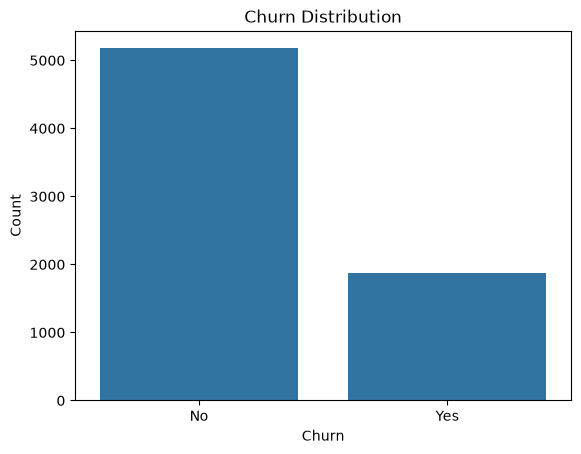

In [22]:
sns.countplot(data=churn_df, x='Churn')

plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

### Conclusion

The dataset contains 7,043 customer records and 21 variables, with no duplicate rows or missing values detected initially. Converting TotalCharges to numeric revealed 11 blank values, all associated with customers who have zero tenure, so these should be handled during preprocessing. About 26.5% of customers churned, compared with 73.5% who stayed, indicating a class imbalance to consider during model development.

## 2. EXPLORATORY DATA ANALYSIS

Questions to explore

1. How does churn vary across contract types, and does the relationship differ by customer tenure?
2. Are customers with higher monthly charges more likely to churn, especially among month-to-month customers?
3. How do tenure and total charges relate to churn? Are newer customers more likely to leave?
4. Does churn differ by internet service type, and is it associated with having online security or tech support?
5. Are customers who use electronic checks more likely to churn than those using automatic payment methods?
6. Do customers with multiple services, such as phone and internet, churn at different rates from customers with fewer services?
7. How do partner or dependent status relate to tenure and churn?
8. Does churn vary by senior-citizen status, and does contract type change that pattern?
9. Are paperless billing and payment method related, and how do those combinations relate to churn?
